## Homework 4: Investment Portfolio Risk Analysis

## Topics

-   Important Distributions

-   Expected Value

-   Variance

-   Scenario

DATA-605, Computational Mathematics, Fall 2026

Supervised by: **Professor Jose Jorge Pagan**


Submitted by: **Mehreen Ali Gillani**


### Introduction
An investment advisory firm is evaluating three portfolios for a risk-sensitive client. This assignment analyzes three investment portfolios (A, B, and C) to support risk-based recommendations for conservative, moderate, and aggressive investors. Using probability-weighted returns, I compute each portfolio's expected return, variance, and standard deviation, then validate these results through Monte Carlo simulation with 10,000 draws per portfolio. Finally, I estimate each portfolio's probability of loss and match it to investor risk tolerance, providing numerical evidence for each recommendation.


**Dataset:** portfolio_returns.csv

### Import Libraries 

In [35]:
# import necessary libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


In [47]:
# Load the dataset
df = pd.read_csv('https://raw.githubusercontent.com/mehreengillani/DATA605/refs/heads/main/portfolio_returns.csv')
df.head(5)

,Portfolio,Return,Probability
0,A,0.15,0.3
1,A,0.08,0.5
2,A,-0.05,0.2
3,B,0.10,0.4
4,B,0.06,0.4


## Part A: Statistical Analysis

**For each portfolio:**

### Compute expected return.




In [37]:
# Expected return per portfolio
expected = df.groupby("Portfolio").apply(
    lambda g: np.sum(g["Return"] * g["Probability"]),
    include_groups=False
).rename("Expected_Return")

print("Expected Returns per Portfolio:")
print(expected)

Expected Returns per Portfolio:
Portfolio
A    0.075
B    0.060
C    0.056
Name: Expected_Return, dtype: float64


### Compute variance.

In [38]:
# Variance per portfolio
variance = df.groupby("Portfolio").apply(
    lambda g: np.sum(g["Probability"] * (g["Return"] - np.sum(g["Return"] * g["Probability"]))**2),
    include_groups=False
).rename("Variance")
print("\nVariance per Portfolio:")
print(variance)



Variance per Portfolio:
Portfolio
A    0.004825
B    0.001920
C    0.000564
Name: Variance, dtype: float64


### Compute standard deviation.

In [39]:
# Standard deviation
results = pd.concat([expected, variance], axis=1)
results["Std_Dev"] = np.sqrt(results["Variance"])
print("\nPortfolio Results (Expected Return, Variance, Std Dev):")
print(results.round(6))


Portfolio Results (Expected Return, Variance, Std Dev):
           Expected_Return  Variance   Std_Dev
Portfolio                                     
A                    0.075  0.004825  0.069462
B                    0.060  0.001920  0.043818
C                    0.056  0.000564  0.023749


**Interpretation:** 

-   Portfolio A has the highest expected return (7.5%), C has the lowest (5.6%).

-   Portfolio A has the highest variance (most risky), C has the lowest (least risky)

-   Portfolio A's returns typically swing about ±6.95% around its mean; C only swings about ±2.37%.


-   A		Highest return, highest risk

-   B		Medium return, medium risk

-   C		Lowest return, lowest risk

### Part B: Monte Carlo Simulation

#### Simulate 10,000 returns for each portfolio.


In [40]:
np.random.seed(42)   # for reproducibility

n_sims = 10_000
simulations = {}

for portfolio, group in df.groupby("Portfolio"):
    returns = group["Return"].values
    probs   = group["Probability"].values
    
    # Randomly pick returns according to their probabilities
    draws = np.random.choice(returns, size=n_sims, p=probs)
    simulations[portfolio] = draws

# Convert to DataFrame for easy comparison
sim_df = pd.DataFrame(simulations)
print(sim_df.head())

      A     B     C
0  0.08  0.10  0.05
1 -0.05  0.10  0.07
2  0.08  0.10  0.07
3  0.08  0.06  0.05
4  0.15  0.06  0.07


##### Compare the return distributions.


In [41]:
summary = sim_df.agg(["mean", "std", "min", "max"]).T
summary.columns = ["Sim_Mean", "Sim_Std", "Min", "Max"]
print(summary.round(4))

   Sim_Mean  Sim_Std   Min   Max
A    0.0759   0.0692 -0.05  0.15
B    0.0594   0.0439 -0.02  0.10
C    0.0560   0.0236 -0.01  0.07


**Comparison:** Portfolio A has the widest spread of returns (min = −5%, max = +15%), indicating the highest risk. Portfolio B is moderately spread (min = −2%, max = +10%). Portfolio C has the tightest range (min = −1%, max = +7%), confirming it is the least volatile portfolio.

**Interpretation:** The simulated means (A: 0.0759, B: 0.0594, C: 0.0560) and standard deviations (A: 0.0692, B: 0.0439, C: 0.0236) match the exact values from Part A within ±0.001. 

This confirms the Monte Carlo simulation accurately reproduces each portfolio's theoretical distribution, a direct demonstration of the Law of Large Numbers.



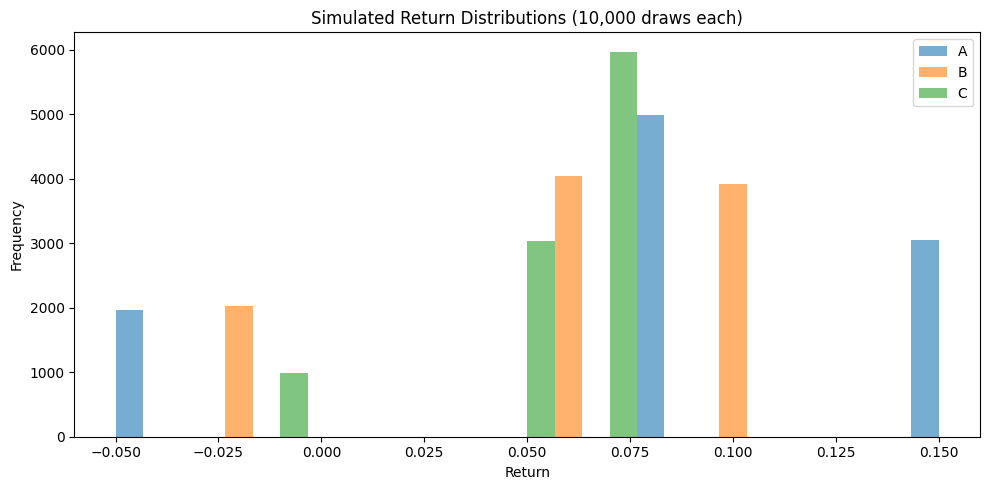

In [42]:
sim_df.plot.hist(bins=30, alpha=0.6, figsize=(10, 5))
plt.title("Simulated Return Distributions (10,000 draws each)")
plt.xlabel("Return")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

**Interpretation:** Portfolio A's histogram is the widest (spanning −5% to +15%), reflecting its high volatility. Portfolio C is tightly clustered near its mean (5.6%), confirming it is the safest option.

##### Estimate the probability of a loss.

In [43]:
loss_prob = (sim_df < 0).mean()
print("Estimated Probability of Loss:")
print(loss_prob.round(4))

Estimated Probability of Loss:
A    0.1962
B    0.2033
C    0.0988
dtype: float64


**Summary:** Monte Carlo simulation closely matches the theoretical loss probabilities:
- Portfolio A: 19.62% vs. 20% theoretical
- Portfolio B: 20.33% vs. 20% theoretical
- Portfolio C: 9.88% vs. 10% theoretical

All estimates are within ±0.4%, confirming the simulation is accurate and Portfolio C is the safest choice.

### Part C: Investment Recommendation

**Prepare a recommendation for:**

-   Conservative investors

-   Moderate investors

-   Aggressive investors

Support your recommendation with numerical evidence.

In [44]:

# ---------- Part A: Exact stats ----------
stats = df.groupby("Portfolio").apply(
    lambda g: pd.Series({
        "Expected_Return": np.sum(g.Return * g.Probability),
        "Variance": np.sum(g.Probability * (g.Return - np.sum(g.Return * g.Probability))**2),
        "P_Loss": g.loc[g.Return < 0, "Probability"].sum()
    }), include_groups=False
)
stats["Std_Dev"] = np.sqrt(stats["Variance"])
stats["Sharpe"] = stats["Expected_Return"] / stats["Std_Dev"]   # return per unit of risk

print(stats.round(4))

           Expected_Return  Variance  P_Loss  Std_Dev  Sharpe
Portfolio                                                    
A                    0.075    0.0048     0.2   0.0695  1.0797
B                    0.060    0.0019     0.2   0.0438  1.3693
C                    0.056    0.0006     0.1   0.0237  2.3580


In [45]:
picks = {
    "Conservative": stats["Std_Dev"].idxmin(),        # lowest risk 
    "Moderate":     stats["Std_Dev"].sort_values().index[1],  # middle risk 
    "Aggressive":   stats["Expected_Return"].idxmax() # highest return 
}


for investor, p in picks.items():
    row = stats.loc[p]
    print(f"{investor:>12} investor → Portfolio {p}  "
          f"(E[R]={row.Expected_Return:.2%}, "
          f"σ={row.Std_Dev:.2%}, "
          f"P(Loss)={row.P_Loss:.0%}, "
          f"Sharpe={row.Sharpe:.2f})")

Conservative investor → Portfolio C  (E[R]=5.60%, σ=2.37%, P(Loss)=10%, Sharpe=2.36)
    Moderate investor → Portfolio B  (E[R]=6.00%, σ=4.38%, P(Loss)=20%, Sharpe=1.37)
  Aggressive investor → Portfolio A  (E[R]=7.50%, σ=6.95%, P(Loss)=20%, Sharpe=1.08)


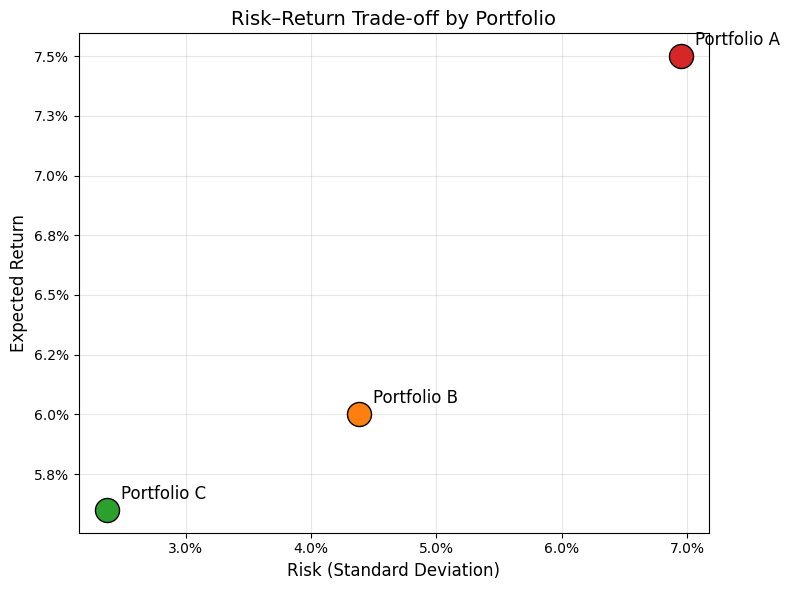

In [46]:
fig, ax = plt.subplots(figsize=(8, 6))

colors = {"A": "#d62728", "B": "#ff7f0e", "C": "#2ca02c"}

for p in stats.index:
    ax.scatter(stats.loc[p, "Std_Dev"], stats.loc[p, "Expected_Return"],
               s=300, color=colors[p], edgecolor="black", zorder=3)
    ax.annotate(f"Portfolio {p}",
                (stats.loc[p, "Std_Dev"], stats.loc[p, "Expected_Return"]),
                xytext=(10, 8), textcoords="offset points", fontsize=12)

ax.set_xlabel("Risk (Standard Deviation)", fontsize=12)
ax.set_ylabel("Expected Return", fontsize=12)
ax.set_title("Risk–Return Trade-off by Portfolio", fontsize=14)
ax.grid(alpha=0.3)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f"{y:.1%}"))
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.1%}"))
plt.tight_layout()
plt.show()

#### Why Each Pick Makes Sense

**Conservative Investor → Portfolio C**

-   Lowest risk: σ = 2.37% (about 1/3 of A's volatility)

-   Lowest chance of loss: only 10% (confirmed by Monte Carlo: 9.88%)

-   Highest Sharpe ratio: 2.36 — best return per unit of risk

-   Trade-off: slightly lower expected return (5.60%)

**Moderate Investor → Portfolio B**

-   Middle risk: σ = 4.38% — balanced between C and A

-   Solid return: 6.00% expected

-   Good Sharpe: 1.37, second-best risk-adjusted return

-   Same loss chance as A (20%) but a much smaller loss (−2% vs. −5%)

-   Best balance of growth and safety

**Aggressive Investor → Portfolio A**

-   Highest expected return: 7.50%

-   Highest volatility: σ = 6.95%  — largest swings

-   Largest potential loss: −5%

-   Lowest Sharpe: 1.08, accepts more risk per unit of return

-   Suitable only for investors who can tolerate significant short-term swings

### Final Recommendation

Based on the numerical evidence, I recommend:

- **Conservative investors → Portfolio C**: With the lowest standard deviation (σ = 2.37%), the lowest probability of loss (10%), and the highest Sharpe ratio (2.36), Portfolio C is the safest option. It offers the best risk-adjusted return despite a slightly lower expected return (5.60%).

- **Moderate investors → Portfolio B**: Portfolio B provides a balanced profile with σ = 4.38%, an expected return of 6.00%, and a Sharpe ratio of 1.37. It sits between the safety of C and the growth potential of A, making it suitable for investors willing to accept moderate risk.

- **Aggressive investors → Portfolio A**: Portfolio A has the highest expected return (7.50%) but also the highest volatility (σ = 6.95%) and the largest potential loss (−5%). It is appropriate only for investors who can tolerate significant short-term swings in pursuit of higher returns.

All recommendations are supported by both the exact calculations (Part A) and the Monte Carlo simulation (Part B), which produced nearly identical statistics.

Risk and return move together.  Portfolio C is safest but lowest-yielding; A is highest-yielding but riskiest; B sits in the middle. 
The right choice depends entirely on the investor's tolerance for volatility and loss.

*End of Assignment*